# Lab 11 · Quantum causal inference: common causes, cause–effect, and the map of the field

**Levels 6–7 · Quantum causal models → Quantum Causal AI research** · Prerequisite lessons: L6-01 (Quantum common causes), L6-02 (Channels in the Choi representation), L6-03 (Quantum DAGs and Markov assumptions), L6-05 (Discovery and informational access), L7-05 (Identifiability before quantum causal learning).

**What you'll learn**

- How to read a Bell/CHSH test as a causal-compatibility test for a graph with a hidden common cause. Why a quantum common cause escapes the classical bound [@bell; @chsh; @allen].
- How, in one specific measurement protocol, a quantum common cause (a shared state) and a quantum cause–effect link (a channel) fill two *different* tetrahedra of Pauli correlations. What that does and does not let you infer.
- How quantum causal models, indefinite causal order, and quantum machine learning relate as research programs.

:::{important} Three different research programs
Quantum causal models ask how causal structure constrains quantum systems that sit at the nodes of an ordinary DAG [@allen; @barrett; @costa]. Indefinite causal order studies processes with no definite order at all, such as the quantum switch [@ocb; @switch; @process]. Quantum machine learning studies learning algorithms that use quantum states or circuits [@qml]. The three share mathematics, not conclusions. This lab is mostly about the first.
:::

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/11-quantum-causal-inference.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math, itertools
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import plotly.graph_objects as go
from qcai import science as s
from qcai.viz import show

np.set_printoptions(precision=4, suppress=True)
SQ2 = math.sqrt(2)
PAULI = (s.X, s.Y, s.Z)

## Part A · Bell's theorem as a causal-compatibility test

Consider the graph below. A hidden common cause $\Lambda$ influences both outcomes $A$ and $B$. The settings $X$ and $Y$ are chosen freely, and each influences only its own side. If $\Lambda$ is a *classical* variable, the graph implies

$$
p(a,b\mid x,y)=\sum_\lambda p(\lambda)\,p(a\mid x,\lambda)\,p(b\mid y,\lambda),
$$

and every such model satisfies $|S|\le2$ for the CHSH combination [@bell; @chsh]. Now suppose the common cause is a *quantum* system shared by the two sides. The Born rule replaces the sum, and $|S|$ can reach $2\sqrt2$. Allen *et al.* point out that Bell correlations cannot be explained the way Reichenbach's principle would seem to demand. They develop a quantum version of that principle and of causal models [@allen].

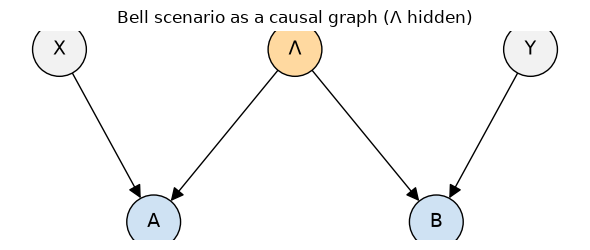

In [3]:
G = nx.DiGraph([("Λ", "A"), ("Λ", "B"), ("X", "A"), ("Y", "B")])
pos = {"X": (0, 1), "A": (0.6, 0), "Λ": (1.5, 1), "B": (2.4, 0), "Y": (3, 1)}
fig, ax = plt.subplots(figsize=(6, 2.6))
nx.draw_networkx(G, pos, ax=ax, node_size=1500, node_color=["#f2f2f2" if n in "XY" else ("#ffd9a0" if n == "Λ" else "#cfe2f3") for n in G],
                 font_size=14, arrowsize=20, edgecolors="black")
ax.set_title("Bell scenario as a causal graph (Λ hidden)"); ax.axis("off")
plt.tight_layout(); plt.show()
assert set(G.predecessors("A")) == {"Λ", "X"} and set(G.predecessors("B")) == {"Λ", "Y"}
assert not nx.has_path(G, "X", "B") and not nx.has_path(G, "Y", "A")      # no setting influences the far outcome

:::{note} Predict
Generate thousands of random *classical* models of this graph, including stochastic response functions. Will any of them exceed $|S|=2$?
:::

In [4]:
g = np.random.default_rng(0)

def chsh_from_local_model(p_lam, pa, pb):
    """p_lam[l], pa[l,x] = P(a=+1|x,l), pb[l,y] = P(b=+1|y,l). Returns S."""
    Ea, Eb = 2 * pa - 1, 2 * pb - 1                 # local expectations, outcomes +-1
    E = lambda x, y: float(np.sum(p_lam * Ea[:, x] * Eb[:, y]))
    return E(0, 0) + E(0, 1) + E(1, 0) - E(1, 1)

S_classical = []
for _ in range(5000):
    L = int(g.integers(1, 9))
    p_lam = g.dirichlet(np.ones(L) * g.choice([0.2, 1.0]))
    sharp = g.random() < 0.5                         # half the models use deterministic responses
    pa = g.integers(0, 2, (L, 2)).astype(float) if sharp else g.random((L, 2))
    pb = g.integers(0, 2, (L, 2)).astype(float) if sharp else g.random((L, 2))
    S_classical.append(chsh_from_local_model(p_lam, pa, pb))
S_classical = np.array(S_classical)
print(f"5000 random classical common-cause models: max |S| = {np.abs(S_classical).max():.4f}")
assert np.abs(S_classical).max() <= 2 + 1e-12

vs = np.round(np.linspace(0.5, 1.0, 11), 2)
S_quantum = {v: s.horodecki_max_chsh(s.werner(float(v))) for v in vs}
assert abs(S_quantum[1.0] - 2 * SQ2) < 1e-12
assert abs(s.chsh_value(s.dm(s.bell_state()), 0, math.pi / 2, math.pi / 4, -math.pi / 4) - 2 * SQ2) < 1e-12

fig = go.Figure([
    go.Histogram(x=S_classical, nbinsx=80, name="classical common cause (random models)", marker_color="#4c78a8"),
    go.Scatter(x=[S_quantum[1.0]] * 2, y=[0, 400], mode="lines", name="quantum common cause, Werner state",
               line=dict(color="crimson", width=4)),
    go.Scatter(x=[2, 2, None, -2, -2], y=[0, 400, None, 0, 400], mode="lines", name="classical bound |S| = 2",
               line=dict(color="black", dash="dash")),
])
steps = [dict(method="restyle", label=f"{v:.2f}", args=[{"x": [[S_quantum[v]] * 2]}, [1]]) for v in vs]
fig.update_layout(height=470, title="CHSH values: classical vs quantum common causes", xaxis_title="S", yaxis_title="count",
                  xaxis_range=[-3, 3], legend=dict(x=0.01, y=0.99),
                  sliders=[dict(active=len(vs) - 1, currentvalue=dict(prefix="Werner visibility v = "), pad=dict(t=50), steps=steps)])
show(fig)

5000 random classical common-cause models: max |S| = 2.0000


**Explain.** No classical model of the graph exceeds $|S|=2$, as the theorem says. The deterministic ones reach the bound. A shared $|\Phi^+\rangle$ reaches $2\sqrt2$. In causal language, the observed distribution is incompatible with the graph if $\Lambda$ is classical, yet compatible if $\Lambda$ may be quantum. This reading still rests on the Bell-test assumptions: free settings, and no influence from $X$ to $B$ or from $Y$ to $A$. These are causal assumptions themselves.

Causal-compatibility constraints go beyond Bell inequalities. Chaves, Majenz, and Gross give a general algorithm for information-theoretic (entropic) constraints on the correlations that a given causal structure can produce [@chaves]. It applies to classical and quantum variables alike. We do not implement it here.

## Part B · Common cause or cause–effect? A two-tetrahedra computation

Take two qubits, $A$ and $B$, and two causal hypotheses:

1. Common cause: $A$ and $B$ are two halves of a shared state $\rho_{AB}$, and both are measured.
2. Cause–effect: $A$ is measured, then sent through a channel $\mathcal E$ to become $B$, which is measured.

We use a single, fixed protocol for both. For each $i\in\{x,y,z\}$, measure $\sigma_i$ on $A$ and $\sigma_i$ on $B$, and record the correlation $c_i=\mathbb E[ab]$. In the cause–effect case, $A$ starts maximally mixed, and the measurement on $A$ leaves it in the eigenstate it found. Then

$$
c_i^{\rm cc}=\operatorname{Tr}\!\big[\rho_{AB}\,\sigma_i\otimes\sigma_i\big],\qquad
c_i^{\rm ce}=\tfrac12\operatorname{Tr}\!\big[\sigma_i\,\mathcal E(\sigma_i)\big]=\tfrac12\operatorname{Tr}\!\big[(\sigma_i^{\top}\otimes\sigma_i)\,J(\mathcal E)\big],
$$

where $J$ is the Choi matrix. Note that $\sigma_y^\top=-\sigma_y$. So the cause–effect formula is *not* just the common-cause formula applied to the normalized Choi state $J/2$: the $y$ component flips sign. The code simulates the measure-and-send protocol directly and checks this identity.

:::{note} Predict
The identity channel sends $A$ to $B$ unchanged. What triple $(c_x,c_y,c_z)$ does it produce? Can any shared state produce the same triple?
:::

In [5]:
def cc_corr(rho):
    return np.array([np.real(np.trace(rho @ s.kron(P, P))) for P in PAULI])

def ce_corr_protocol(K):
    """Simulate: A maximally mixed, measure sigma_i (outcome a, eigenstate kept), send through E, measure sigma_i on B."""
    c = []
    for P in PAULI:
        tot = 0.0
        for a in (1, -1):
            post = (s.I2 + a * P) / 2                          # post-measurement state, probability 1/2
            tot += 0.5 * a * np.real(np.trace(P @ s.apply_kraus(post, K)))   # 0.5 * a * E[b | a]
        c.append(tot)
    return np.array(c)

def ce_corr_choi(K):
    J = s.choi(K)
    return np.array([np.real(np.trace(s.kron(P.T, P) @ J)) / 2 for P in PAULI])

def random_state(rank):
    Gm = g.normal(size=(4, rank)) + 1j * g.normal(size=(4, rank)); r = Gm @ Gm.conj().T
    return r / np.trace(r)

def random_channel(m):
    """Random Stinespring isometry C^2 -> C^2 (x) C^m; Kraus K_k = (I (x) <k|) V."""
    Gm = g.normal(size=(2 * m, 2 * m)) + 1j * g.normal(size=(2 * m, 2 * m))
    V = np.linalg.qr(Gm)[0][:, :2].reshape(2, m, 2)
    return [V[:, k, :] for k in range(m)]

cc_pts = [cc_corr(random_state(int(g.integers(1, 5)))) for _ in range(1500)]
ce_pts = []
for _ in range(1500):
    K = random_channel(int(g.integers(1, 5)))
    assert s.is_cptp(K)
    c = ce_corr_protocol(K)
    assert np.allclose(c, ce_corr_choi(K), atol=1e-12)          # protocol == Choi formula with sigma^T
    ce_pts.append(c)
# extremal examples: Bell states (common cause) and Pauli unitaries (cause-effect)
bell_vertices = {n: cc_corr(s.dm(s.bell_state(n))) for n in ("phi+", "phi-", "psi+", "psi-")}
unitary_vertices = {n: ce_corr_protocol([U]) for n, U in (("I", s.I2), ("X", s.X), ("Y", s.Y), ("Z", s.Z))}
for d in (bell_vertices, unitary_vertices):
    for k, v in d.items():
        print(f"{k:5s} -> {v}")
cc_pts = np.array(cc_pts + list(bell_vertices.values()))
ce_pts = np.array(ce_pts + list(unitary_vertices.values()))
assert np.allclose(unitary_vertices["I"], [1, 1, 1]) and np.allclose(bell_vertices["phi+"], [1, -1, 1])
# The Choi state of the identity channel is |Phi+>: its *state* correlations are (1,-1,1), not (1,1,1)
assert np.allclose(cc_corr(s.choi([s.I2]) / 2), [1, -1, 1])

phi+  -> [ 1. -1.  1.]
phi-  -> [-1.  1.  1.]
psi+  -> [ 1.  1. -1.]
psi-  -> [-1. -1. -1.]
I     -> [1. 1. 1.]
X     -> [ 1. -1. -1.]
Y     -> [-1.  1. -1.]
Z     -> [-1. -1.  1.]


Now test which region each family occupies. A point is in the common-cause tetrahedron $T_{\rm cc}$ when the four numbers $\tfrac14(1+c_x-c_y+c_z)$, $\tfrac14(1-c_x+c_y+c_z)$, $\tfrac14(1+c_x+c_y-c_z)$, $\tfrac14(1-c_x-c_y-c_z)$ are all $\ge0$. These are the Bell-state weights of the Bell-diagonal state with these correlations. A point is in the cause–effect tetrahedron $T_{\rm ce}$ when $\tfrac14(1+c_x+c_y+c_z)$, $\tfrac14(1+c_x-c_y-c_z)$, $\tfrac14(1-c_x+c_y-c_z)$, $\tfrac14(1-c_x-c_y+c_z)$ are all $\ge0$. These are the Pauli-channel weights. $T_{\rm ce}$ is the mirror image of $T_{\rm cc}$ under $c_y\to-c_y$. Their intersection is the octahedron $|c_x|+|c_y|+|c_z|\le1$.

In [6]:
def w_cc(c):
    x, y, z = c[..., 0], c[..., 1], c[..., 2]
    return np.stack([1 + x - y + z, 1 - x + y + z, 1 + x + y - z, 1 - x - y - z], -1) / 4

def w_ce(c):
    x, y, z = c[..., 0], c[..., 1], c[..., 2]
    return np.stack([1 + x + y + z, 1 + x - y - z, 1 - x + y - z, 1 - x - y + z], -1) / 4

tol = 1e-12
assert np.all(w_cc(cc_pts) >= -tol)          # every sampled state lies in T_cc
assert np.all(w_ce(ce_pts) >= -tol)          # every sampled channel lies in T_ce
cc_out = np.any(w_ce(cc_pts) < -tol, axis=1)
ce_out = np.any(w_cc(ce_pts) < -tol, axis=1)
in_oct = lambda P: np.abs(P).sum(axis=1) <= 1 + tol
# outside the other tetrahedron <=> outside the octahedron (for points inside their own tetrahedron)
assert np.array_equal(cc_out, ~in_oct(cc_pts)) and np.array_equal(ce_out, ~in_oct(ce_pts))
print(f"common-cause samples outside T_ce (unambiguous): {cc_out.mean():.1%}")
print(f"cause-effect samples outside T_cc (unambiguous): {ce_out.mean():.1%}")

# product states (no entanglement) never leave the octahedron: c_i = a_i b_i, so sum |c_i| <= |a||b| <= 1
for _ in range(500):
    ra = s.dm(s.ket(*g.uniform(0, math.pi, 2))); rb = s.dm(s.ket(*g.uniform(0, math.pi, 2)))
    assert np.abs(cc_corr(np.kron(ra, rb))).sum() <= 1 + 1e-12

# Twirl check (the proof idea): averaging rho over {I, XX, YY, ZZ} conjugations keeps c and gives a
# Bell-diagonal state whose Bell weights are exactly w_cc(c) -- so w_cc(c) >= 0 for EVERY state.
bells = [s.dm(s.bell_state(n)) for n in ("phi+", "phi-", "psi+", "psi-")]
for _ in range(50):
    rho = random_state(4)
    tw = sum(s.kron(P, P) @ rho @ s.kron(P, P).conj().T for P in (s.I2,) + PAULI) / 4
    assert np.allclose(cc_corr(tw), cc_corr(rho))
    assert np.allclose(tw, sum(w * b for w, b in zip(w_cc(cc_corr(rho)), bells)))
# The analogous Pauli twirl of a channel gives a Pauli channel with weights w_ce(c).
for _ in range(50):
    K = random_channel(3)
    twK = [P @ k @ Q / 2 for Q in (s.I2,) + PAULI for k in K for P in [Q.conj().T]]
    assert s.is_cptp(twK) and np.allclose(ce_corr_protocol(twK), ce_corr_protocol(K))
    probe = random_state(2)[:2, :2]; probe = probe / np.trace(probe)
    pauli_ch = sum(w * Pm @ probe @ Pm for w, Pm in zip(w_ce(ce_corr_protocol(K)), (s.I2,) + PAULI))
    assert np.allclose(s.apply_kraus(probe, twK), pauli_ch)
print("twirling checks passed: states map to Bell-diagonal states, channels to Pauli channels, with c unchanged")

common-cause samples outside T_ce (unambiguous): 23.1%
cause-effect samples outside T_cc (unambiguous): 32.0%
twirling checks passed: states map to Bell-diagonal states, channels to Pauli channels, with c unchanged


The interactive figure shows both clouds and both tetrahedra. Rotate it, and use the buttons to show one family at a time. Blue: shared states. Red: channels.

In [7]:
def tetra_mesh(verts, color, name):
    V = np.array(verts)
    faces = list(itertools.combinations(range(4), 3))
    return go.Mesh3d(x=V[:, 0], y=V[:, 1], z=V[:, 2], i=[f[0] for f in faces], j=[f[1] for f in faces],
                     k=[f[2] for f in faces], color=color, opacity=0.12, name=name, showlegend=True, hoverinfo="skip")

def tetra_edges(verts, color):
    V = np.array(verts); xs, ys, zs = [], [], []
    for a, b in itertools.combinations(range(4), 2):
        xs += [V[a, 0], V[b, 0], None]; ys += [V[a, 1], V[b, 1], None]; zs += [V[a, 2], V[b, 2], None]
    return go.Scatter3d(x=xs, y=ys, z=zs, mode="lines", line=dict(color=color, width=4), showlegend=False, hoverinfo="skip")

Vcc, Vce = list(bell_vertices.values()), list(unitary_vertices.values())
traces = [
    go.Scatter3d(x=cc_pts[:, 0], y=cc_pts[:, 1], z=cc_pts[:, 2], mode="markers", marker=dict(size=2, color="#4c78a8"),
                 name="common cause: random ρ_AB", hovertemplate="c=(%{x:.2f}, %{y:.2f}, %{z:.2f})"),
    tetra_mesh(Vcc, "#4c78a8", "T_cc (Bell states at vertices)"), tetra_edges(Vcc, "#4c78a8"),
    go.Scatter3d(x=ce_pts[:, 0], y=ce_pts[:, 1], z=ce_pts[:, 2], mode="markers", marker=dict(size=2, color="crimson"),
                 name="cause–effect: random channel E", hovertemplate="c=(%{x:.2f}, %{y:.2f}, %{z:.2f})"),
    tetra_mesh(Vce, "crimson", "T_ce (Pauli unitaries at vertices)"), tetra_edges(Vce, "crimson"),
    go.Scatter3d(x=[v[0] for v in Vcc + Vce], y=[v[1] for v in Vcc + Vce], z=[v[2] for v in Vcc + Vce], mode="text",
                 text=["Φ+", "Φ−", "Ψ+", "Ψ−", "I", "X", "Y", "Z"], showlegend=False, hoverinfo="skip"),
]
fig = go.Figure(traces)
show_cc = [True, True, True, False, False, False, True]
show_ce = [False, False, False, True, True, True, True]
fig.update_layout(height=660, title="Pauli correlations (c_x, c_y, c_z): common cause vs cause–effect",
                  margin=dict(l=0, r=0, t=60, b=0), legend=dict(x=0, y=0.9),
                  scene=dict(aspectmode="cube", xaxis_title="c_x", yaxis_title="c_y", zaxis_title="c_z"),
                  updatemenus=[dict(type="buttons", direction="right", x=0, y=1.08, xanchor="left", buttons=[
                      dict(label="both", method="restyle", args=[{"visible": [True] * 7}]),
                      dict(label="common cause", method="restyle", args=[{"visible": show_cc}]),
                      dict(label="cause–effect", method="restyle", args=[{"visible": show_ce}])])])
show(fig)

**Explain.** In this protocol:

- every shared state lands in $T_{\rm cc}$, whose vertices are the four Bell states; every channel lands in $T_{\rm ce}$, whose vertices are the four Pauli unitaries;
- the two regions are exactly these tetrahedra, not just "clouds inside" them. The sampled points are evidence, but the *proof* is short. The twirling checks above show that every state's triple equals that of a Bell-diagonal state with weights $w_{\rm cc}(c)\ge0$. Every channel's triple equals that of a Pauli channel with weights $w_{\rm ce}(c)\ge0$. Conversely, mixtures of Bell states (or of Pauli unitaries) reach every point of the tetrahedron, and the map to $c$ is linear;
- a point outside the octahedron is compatible with only one of the two hypotheses. Product states never leave the octahedron (checked above). Neither do their mixtures, since the octahedron is convex. So in this protocol, an unambiguous "common cause" verdict requires entanglement.

**What this does not show.** It does not handle mixtures of the two structures (probabilistic or coherent combinations). It does not handle a non-maximally-mixed input at $A$, other measurement schemes, or finite-sample error. A point inside the octahedron leaves the question open. And it is not a general theorem about quantum versus classical causal discovery.

The question and the measure-and-send protocol of Part B come from Ried *et al.*, who also report a photonic experiment [@ried2015]. They frame the result as a quantum advantage for causal inference. This lab does not adopt that framing.

Liu *et al.* give a full observational scheme that distinguishes five causal structures for a bipartite system measured at two times [@hypothesis]. They work with the space-time pseudo-density matrix. They prove that, without signalling between the subsystems, its reduced state cannot have negativity. The computation above is a simpler, separate toy. It does not reproduce that paper. Costa and Shrapnel develop the broader framework of process-based quantum causal modelling, with quantum analogues of the causal Markov condition and faithfulness [@costa].

## Part C · A map of the field

The concept graph below places the main ideas of this course's last levels. Hover over a node for the reference. Colours mark the research program. Use the buttons to highlight one program.

| node | program | reference |
|----|----|----|
| Structural causal models, do-calculus | classical causal inference | [@pearl] |
| Causal discovery from independences | classical causal inference | [@spirtes; @peters] |
| Bell / CHSH | bridge | [@bell; @chsh] |
| Quantum common causes, quantum Reichenbach principle | quantum causal models | [@allen] |
| Unitary-based quantum causal models, quantum d-separation and do-calculus | quantum causal models | [@barrett] |
| Process-based quantum causal modelling (Markov, faithfulness) | quantum causal models | [@costa] |
| Entropic constraints on quantum causal structures | quantum causal models | [@chaves] |
| Causally neutral quantum Bayesian inference | quantum causal models | [@leifer] |
| Causal tomography; common cause vs cause–effect from correlations | quantum causal models | [@ried2015] |
| Observational causal inference with the pseudo-density matrix | quantum causal models | [@hypothesis] |
| Process matrices, causal inequalities | indefinite causal order | [@ocb] |
| Quantum combs, higher-order maps | indefinite causal order | [@chiribella] |
| Quantum switch | indefinite causal order | [@switch] |
| Causal witnesses, causal nonseparability | indefinite causal order | [@process] |
| Quantum machine learning overview | quantum machine learning | [@qml] |
| Quantum circuit learning | quantum machine learning | [@mitarai] |
| Parameter-shift gradients | quantum machine learning | [@schuld] |
| Quantum kernels | quantum machine learning | [@kernels] |
| Barren plateaus; noise-induced plateaus | quantum machine learning | [@plateaus; @noise] |
| Data and quantum advantage in learning | quantum machine learning | [@advantage] |
| Classical shadows | quantum learning / estimation | [@shadows] |

In [8]:
PROG = {"classical": "#7f7f7f", "QCM": "#4c78a8", "ICO": "#9467bd", "QML": "#e45756", "bridge": "#f2a541", "lab": "#59a14f"}
nodes = {
    "SCMs & do-calculus": ("classical", "Pearl 2009"), "Causal discovery": ("classical", "Spirtes et al. 2000; Peters et al. 2017"),
    "Bell / CHSH": ("bridge", "Bell 1964; Clauser et al. 1969"),
    "Quantum common causes": ("QCM", "Allen et al. 2017"), "Quantum causal models (unitary)": ("QCM", "Barrett, Lorenz, Oreshkov 2019 (arXiv)"),
    "Process-based QCM": ("QCM", "Costa & Shrapnel 2016"), "Entropic constraints": ("QCM", "Chaves, Majenz, Gross 2015"),
    "Causally neutral inference": ("QCM", "Leifer & Spekkens 2013"), "PDM causal inference": ("QCM", "Liu et al. 2025"), "Causal tomography": ("QCM", "Ried et al. 2015"),
    "Process matrices": ("ICO", "Oreshkov, Costa, Brukner 2012"), "Quantum combs": ("ICO", "Chiribella, D'Ariano, Perinotti 2009"),
    "Quantum switch": ("ICO", "Chiribella et al. 2013"), "Causal witnesses": ("ICO", "Araújo et al. 2015"),
    "QML overview": ("QML", "Biamonte et al. 2017"), "Circuit learning": ("QML", "Mitarai et al. 2018"),
    "Parameter shift": ("QML", "Schuld et al. 2019"), "Quantum kernels": ("QML", "Havlicek et al. 2019"),
    "Barren plateaus": ("QML", "McClean et al. 2018; Wang et al. 2021"), "Data & advantage": ("QML", "Huang et al. 2021"),
    "Classical shadows": ("QML", "Huang, Kueng, Preskill 2020"),
    "Lab 6": ("lab", "Entanglement and CHSH"), "Lab 8": ("lab", "Variational gradients"), "Lab 9": ("lab", "Quantum switch"),
    "Lab 10": ("lab", "Classical shadows"), "Lab 11": ("lab", "This lab"),
}
edges = [("SCMs & do-calculus", "Causal discovery"), ("SCMs & do-calculus", "Quantum causal models (unitary)"),
         ("Bell / CHSH", "Quantum common causes"), ("Causal discovery", "Bell / CHSH"),
         ("Quantum common causes", "Quantum causal models (unitary)"), ("Process matrices", "Process-based QCM"),
         ("Quantum common causes", "Entropic constraints"), ("Causally neutral inference", "Quantum common causes"),
         ("Process-based QCM", "PDM causal inference"), ("Quantum combs", "Quantum switch"), ("Process matrices", "Causal witnesses"),
         ("Quantum switch", "Causal witnesses"), ("QML overview", "Circuit learning"), ("Circuit learning", "Parameter shift"),
         ("Circuit learning", "Barren plateaus"), ("QML overview", "Quantum kernels"), ("QML overview", "Data & advantage"),
         ("Data & advantage", "Classical shadows"),
         ("Lab 6", "Bell / CHSH"), ("Lab 8", "Parameter shift"), ("Lab 8", "Barren plateaus"), ("Lab 9", "Quantum switch"),
         ("Lab 10", "Classical shadows"), ("Lab 11", "Quantum common causes"), ("Lab 11", "PDM causal inference"),
         ("Causal tomography", "Quantum common causes"), ("Lab 11", "Causal tomography")]
Gm = nx.Graph(); Gm.add_nodes_from(nodes); Gm.add_edges_from(edges)
assert set(Gm.nodes) == set(nodes) and nx.number_connected_components(Gm) == 2   # {classical, QCM, ICO, ...} and {QML, ...}
qml_comp = nx.node_connected_component(Gm, "QML overview")
assert all(nodes[n][0] in ("QML", "lab") for n in qml_comp)
comps = sorted(nx.connected_components(Gm), key=len, reverse=True)
print("connected components:", [sorted(c)[:3] + ["..."] for c in comps])
posm = nx.spring_layout(Gm, seed=3, k=0.55)

ex, ey = [], []
for a, b in edges:
    ex += [posm[a][0], posm[b][0], None]; ey += [posm[a][1], posm[b][1], None]
traces = [go.Scatter(x=ex, y=ey, mode="lines", line=dict(color="lightgray", width=1.5), hoverinfo="skip", showlegend=False)]
labels = {"classical": "classical causal inference", "QCM": "quantum causal models", "ICO": "indefinite causal order",
          "QML": "quantum machine learning", "bridge": "bridge (Bell)", "lab": "labs in this book"}
order = list(PROG)
for prog in order:
    ns = [n for n, (p, _) in nodes.items() if p == prog]
    traces.append(go.Scatter(x=[posm[n][0] for n in ns], y=[posm[n][1] for n in ns], mode="markers+text", text=ns,
                             textposition="top center", textfont=dict(size=10),
                             marker=dict(size=16, color=PROG[prog], line=dict(color="black", width=1)),
                             hovertext=[f"{n}<br>{nodes[n][1]}" for n in ns], hoverinfo="text", name=labels[prog]))
fig = go.Figure(traces)
def highlight(prog):
    return [1.0] + [1.0 if p == prog or prog == "all" else 0.15 for p in order]
fig.update_layout(height=640, title="Three research programs and how this book's labs connect to them",
                  xaxis=dict(visible=False), yaxis=dict(visible=False), legend=dict(orientation="h", y=-0.05),
                  updatemenus=[dict(type="buttons", direction="right", x=0, y=1.09, xanchor="left", buttons=
                                    [dict(label="all", method="restyle", args=[{"opacity": highlight("all")}])] +
                                    [dict(label=labels[p], method="restyle", args=[{"opacity": highlight(p)}]) for p in ("QCM", "ICO", "QML")])])
show(fig)

connected components: [['Bell / CHSH', 'Causal discovery', 'Causal tomography', '...'], ['Barren plateaus', 'Circuit learning', 'Classical shadows', '...']]


**Explain.** In this map, quantum causal models connect to classical causal inference through Bell's theorem and the do-calculus. They connect to indefinite causal order through process matrices, which Costa and Shrapnel's framework builds on [@costa]. Quantum machine learning forms its own component: none of the edges drawn here link it to causal modelling. The authors of this course chose the map as a teaching summary. It is not a bibliometric analysis. The code only checks its structure: two connected components, one of which contains only QML nodes and labs.

## Going deeper: why the cause–effect correlations involve $\sigma^\top$

Write $J=\sum_{jk}|j\rangle\langle k|\otimes\mathcal E(|j\rangle\langle k|)$. For any operators $M,N$,

$$
\operatorname{Tr}\big[(M\otimes N)J\big]=\sum_{jk}\langle k|M|j\rangle\operatorname{Tr}\big[N\,\mathcal E(|j\rangle\langle k|)\big]=\operatorname{Tr}\big[N\,\mathcal E(M^\top)\big].
$$

With $M=\sigma_i^\top$ and $N=\sigma_i$ this gives $\operatorname{Tr}[\sigma_i\mathcal E(\sigma_i)]$, the cause–effect correlation (times 2). Suppose you use the Choi *state* $J/2$ as if it were a shared state. That silently replaces $\sigma_y$ by $-\sigma_y$ on one side, and this is precisely the mirror that separates the two tetrahedra. The next cell checks the identity for random channels and random $M,N$.

In [9]:
for _ in range(30):
    K = random_channel(int(g.integers(1, 4)))
    M = g.normal(size=(2, 2)) + 1j * g.normal(size=(2, 2)); N = g.normal(size=(2, 2)) + 1j * g.normal(size=(2, 2))
    assert abs(np.trace(np.kron(M, N) @ s.choi(K)) - np.trace(N @ s.apply_kraus(M.T, K))) < 1e-10
print("Tr[(M x N) J] = Tr[N E(M^T)] verified for 30 random channels")

Tr[(M x N) J] = Tr[N E(M^T)] verified for 30 random channels


## Exercises

:::{admonition} Exercise: :label: lab11-ex1
:class: tip
In the protocol of Part B, show that no shared state can produce the identity channel's triple $(1,1,1)$.
:::

:::{dropdown} Solution
The fourth common-cause weight is $\tfrac14(1-c_x-c_y-c_z)=\tfrac14(1-3)=-\tfrac12<0$. So $(1,1,1)\notin T_{\rm cc}$. The observation is incompatible with any common cause in this protocol.
:::

:::{admonition} Exercise: :label: lab11-ex2
:class: tip
A source emits $\tfrac12(|00\rangle\langle00|+|11\rangle\langle11|)$. Compute its triple and its maximal CHSH value. Does perfect $Z$ correlation reveal a quantum common cause?
:::

:::{dropdown} Solution
The triple is $(0,0,1)$, inside the octahedron, so it is compatible with both hypotheses. The correlation matrix is $\mathrm{diag}(0,0,1)$, so the Horodecki value is $2\sqrt{1}=2$: no CHSH violation. Perfect $Z$ correlation alone has a classical explanation (lesson L6-01).
:::

:::{admonition} Exercise: :label: lab11-ex3
:class: tip
The state $\rho_v=v|\Psi^-\rangle\langle\Psi^-|+(1-v)I/4$ has triple $(-v,-v,-v)$. For which $v$ could the same triple come from a channel? Compare with the entanglement threshold of Lab 6.
:::

:::{dropdown} Solution
The cause–effect weights are $\tfrac14(1-3v)$ and three copies of $\tfrac14(1+v)$. All are $\ge0$ exactly when $v\le1/3$. That is also exactly where $\rho_v$ stops being entangled (concurrence $\max(0,(3v-1)/2)$). The Pauli channel with those weights produces the triple.
:::

## Check yourself

In [10]:
assert w_cc(np.array([1.0, 1.0, 1.0]))[3] == -0.5
sep = 0.5 * (s.dm(np.array([1, 0, 0, 0])) + s.dm(np.array([0, 0, 0, 1])))
assert np.allclose(cc_corr(sep), [0, 0, 1]) and abs(s.horodecki_max_chsh(sep) - 2) < 1e-12
for v in np.linspace(0, 1, 21):
    rho_v = v * s.dm(s.bell_state("psi-")) + (1 - v) * np.eye(4) / 4
    c = cc_corr(rho_v)
    assert np.allclose(c, [-v, -v, -v])
    ok_channel = np.all(w_ce(c) >= -1e-12)
    assert ok_channel == (v <= 1 / 3 + 1e-12)
    assert (s.concurrence(rho_v) > 1e-9) == (v > 1 / 3 + 1e-9)
    if ok_channel:   # build the Pauli channel and run the protocol
        Kp = [math.sqrt(max(w, 0)) * P for w, P in zip(w_ce(c), (s.I2,) + PAULI)]
        assert s.is_cptp(Kp) and np.allclose(ce_corr_protocol(Kp), c)
print("All checks passed.")

All checks passed.

## Limits of this model

The Bell reading has assumptions. Classical incompatibility holds under the Bell assumptions: free settings, locality, fair sampling. These are causal assumptions, and experiments must defend them.

We used one protocol. Part B fixes Pauli measurements on both qubits and a maximally mixed input for the cause–effect case. Other protocols give different regions, and some distinguish more structures [@hypothesis].

We tested pure hypotheses only. Real systems may combine a common cause and a direct link, or be in a superposition of causal structures. We model neither.

The expectations are exact, with no finite-sample analysis. With data, a point near a face of the octahedron needs a confidence region before any verdict.

This is not an advantage claim. The computation shows a geometric fact about two model families. It does not show that quantum causal discovery is better than classical discovery for any practical task.

The map is a sketch. Part C summarizes a few connections. It is not a complete or neutral survey of the literature.